In [9]:
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import numpy as np
import sys
import subprocess

# Matplotlib imports
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm

# Scipy imports
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator

# Iris imports
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole

# Path adjustments
from pathlib import Path
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration")
import momentum_fluxes.momentum_flux_funcs as tx

orog_data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

sonde_ids = []

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/" 

raw_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_raw_sonde_data").glob("*.nc"))
coarse_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_coarse_sonde_data").glob("*.nc"))
model_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_model_sonde_data").glob("*.nc"))

index = 3

# Paths for the sonde and model data

sonde_id = raw_sonde_list[index].stem[13:21]

raw_data_path = raw_sonde_list[index]
coarse_data_path = coarse_sonde_list[index]
model_data_path = model_sonde_list[index]

data_path_orog = "orography_u-eb392_run1_0p3km.nc"

original_model_data_path_4 = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"




In [10]:
# Import in some data to see what it looks like
plot_title_affix = f"{sonde_id}"
cubelist_s_path = f"{coarse_data_path}"
cubelist_m_path = f"{model_data_path}"
cubelist_r_path = f"{raw_data_path}"

cubelist_mo_path = f"{original_model_data_path}"
orog_cube_path = f"{data_path_base}/{data_path_orog}"

cubelist_s = iris.load(cubelist_s_path)
cubelist_m = iris.load(cubelist_m_path)
cubelist_mo = iris.load(cubelist_mo_path)
orog_cube = iris.load(orog_cube_path)[0]

#cubelist_m

# %%
# First, extract the relevant cubes 
u_s_wind_nonans, u_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "eastward_wind")
v_s_wind_nonans, v_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "northward_wind")
T_s_nonans, T_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_temperature")
Theta_s_nonans, Theta_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_potential_temperature")
pressure_s_nonans, pressure_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_pressure")

u_m_wind_nonans, u_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "eastward_wind")
v_m_wind_nonans, v_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "northward_wind")
T_m_nonans, T_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_temperature")
Theta_m_nonans, Theta_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_potential_temperature")
pressure_m_nonans, pressure_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_pressure")

u_r_wind_nonans, u_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "eastward_wind")
v_r_wind_nonans, v_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "northward_wind")
T_r_nonans, T_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_temperature")
Theta_r_nonans, Theta_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_potential_temperature")
pressure_r_nonans, pressure_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_pressure")
alt_nonans, alt_mask = tx.nonans_cubedata(cubelist_r_path, "altitude")
time_nonans, time_mask = tx.nonans_cubedata(cubelist_r_path, "Elapsed Time")


# Extract the vert_levels to plot as background
cross_heights = tx.vert_levels_for_sonde(sonde_data_path=cubelist_s_path, 
                                  model_sonde_data_path=cubelist_m_path, 
                                  model_data_path=cubelist_mo_path, 
                                  model_orog_path=orog_cube_path)

Flux_u_s = tx.flux_from_sonde(cubelist_s_path, component="zonal")
Flux_v_s = tx.flux_from_sonde(cubelist_s_path, component="meridional")
Flux_u_m = tx.flux_from_sonde(cubelist_m_path, component="zonal")
Flux_v_m = tx.flux_from_sonde(cubelist_m_path, component="meridional")

Loading zonal wind data and Temperature
Loading in Pressure data and converting into Pascals
Loading in altitude and time data
Data loaded, now fitting polynomials to find means and primes
Means and Perturbations for Wind, Temperature, Pressure found.
Found normalised Temperature
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (5676,)
Flux term calculated, now calculating prefactor


/home/users/jmtd42/miniforge3/envs/teamx/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


Brunt Vaisala Frequency Calculated
Loading meridional wind data and Temperature
Loading in Pressure data and converting into Pascals
Loading in altitude and time data
Data loaded, now fitting polynomials to find means and primes
Means and Perturbations for Wind, Temperature, Pressure found.
Found normalised Temperature
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (5676,)
Flux term calculated, now calculating prefactor
Brunt Vaisala Frequency Calculated
Loading zonal wind data and Temperature
Loading in Pressure data and converting into Pascals
Loading in altitude and time data
Data loaded, now fitting polynomials to find means and primes
Means and Perturbations for Wind, Temperature, Pressure found.
Found normalised Temperature
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (5676,)
Flux term calculated, now calculating prefactor
Brunt Vaisala Frequency Calculated
Loading meridional wind data and Temperature
Loading in Pressu

In [11]:
# Sample points to slice the lat at
lat_cube = cubelist_s.extract_cube("latitude")
lon_cube = cubelist_s.extract_cube("longitude")

lats = lat_cube.data
lons = lon_cube.data

lats.mask = False
lons.mask = False

# Get grid_lat lons
grid_lats = orog_cube.coord("grid_latitude").points
grid_lons = orog_cube.coord("grid_longitude").points

# Convert the points to cubes coord system
coord_system = orog_cube.coord("grid_latitude").coord_system

# Find the pole
pol_lat = coord_system.grid_north_pole_latitude
pol_lon = coord_system.grid_north_pole_longitude


# Rotate the coords, and remove nans
rot_lats_raw, rot_lons_raw = rotate_pole(lats=lats, lons=lons, pole_lat=pol_lat, pole_lon=pol_lon)
rot_lons, lon_mask = tx.fill_nans(rot_lons_raw[::] + 360)
rot_lats, lat_mask = tx.fill_nans(rot_lats_raw[::])


# Create the sample points to slice cube at
grid_sample_points = (grid_lats, grid_lons)
sonde_sample_points = np.column_stack((rot_lats, rot_lons))

orog_data_raw = orog_cube.data
orog_data = orog_data_raw[0,0,::,::]
orog_data.mask=False

# Create interpolator and use it 
orog_interpolator = RegularGridInterpolator(points=grid_sample_points, values=orog_data, method="linear")
orog = orog_interpolator(sonde_sample_points)



In [12]:
# Get the horizontal distance from launch site
dist = cubelist_s.extract_cube("Range of Radiosonde from Launch Site")

distance_raw = dist.data
distance_raw.mask = False

distance_valid = distance_raw.copy()
# Where is the distance going to arbitrarily high values?
distance_invalid_points = np.where(np.abs(distance_raw) > 1e5)

# At these invalid points, let it be nan
distance_valid[distance_invalid_points] = np.nan

# Fill up the nans via linear interpolation
distance, distance_mask = tx.fill_nans(distance_valid)

In [13]:
# Now to figure out how to get information about the vertical levels out
mlevels_cube = cubelist_mo.extract_cube("model_level_number")
surf_alt_cube = cubelist_mo.extract_cube("surface_altitude")
w_cube = cubelist_mo.extract_cube("upward_air_velocity")

# Extract the auxillary coord data
orog_frac = w_cube.aux_coords[0].points
ref_ellip_height = w_cube.aux_coords[1].points

# Level heights
lev_index = mlevels_cube.data

levs_list = []
for i,j in enumerate(lev_index):
    lev_height = ref_ellip_height[i] + orog_frac[i]*orog
    levs_list.append(lev_height)


# Extract the altitude profiles
alt_cube_m = cubelist_m.extract_cube("altitude")
alt_m = alt_cube_m.data

alt_cube_s = cubelist_s.extract_cube("altitude")
alt_s = alt_cube_s.data

In [14]:
print(np.mean(u_s_wind_nonans), np.median(u_s_wind_nonans), np.nanmin(u_s_wind_nonans), np.nanmax(u_s_wind_nonans), np.nanmax(u_s_wind_nonans) - np.nanmin(u_s_wind_nonans))
print(np.mean(v_s_wind_nonans), np.median(v_s_wind_nonans), np.nanmin(v_s_wind_nonans), np.nanmax(v_s_wind_nonans), np.nanmax(v_s_wind_nonans) - np.nanmin(v_s_wind_nonans))
print(np.mean(u_m_wind_nonans), np.median(u_m_wind_nonans), np.nanmin(u_m_wind_nonans), np.nanmax(u_m_wind_nonans), np.nanmax(u_m_wind_nonans) - np.nanmin(u_m_wind_nonans))
print(np.mean(v_m_wind_nonans), np.median(v_m_wind_nonans), np.nanmin(v_m_wind_nonans), np.nanmax(v_m_wind_nonans), np.nanmax(v_m_wind_nonans) - np.nanmin(v_m_wind_nonans))

8.724403669090176 8.625676952372272 -1.5713337435205317 17.989197003467964 19.560530746988498
-0.4145311860675007 -1.9038684894815057 -12.810501595821057 10.48739740472575 23.297899000546806
9.194244249457771 9.20775869700796 -2.786611224758719 18.799255869057344 21.585867093816063
-0.5943135484568379 -2.104910560281997 -9.551125025916942 11.767932053956644 21.319057079873588


/home/users/jmtd42/miniforge3/envs/teamx/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


Text(0.02, 0.5, 'Altitude (m)')

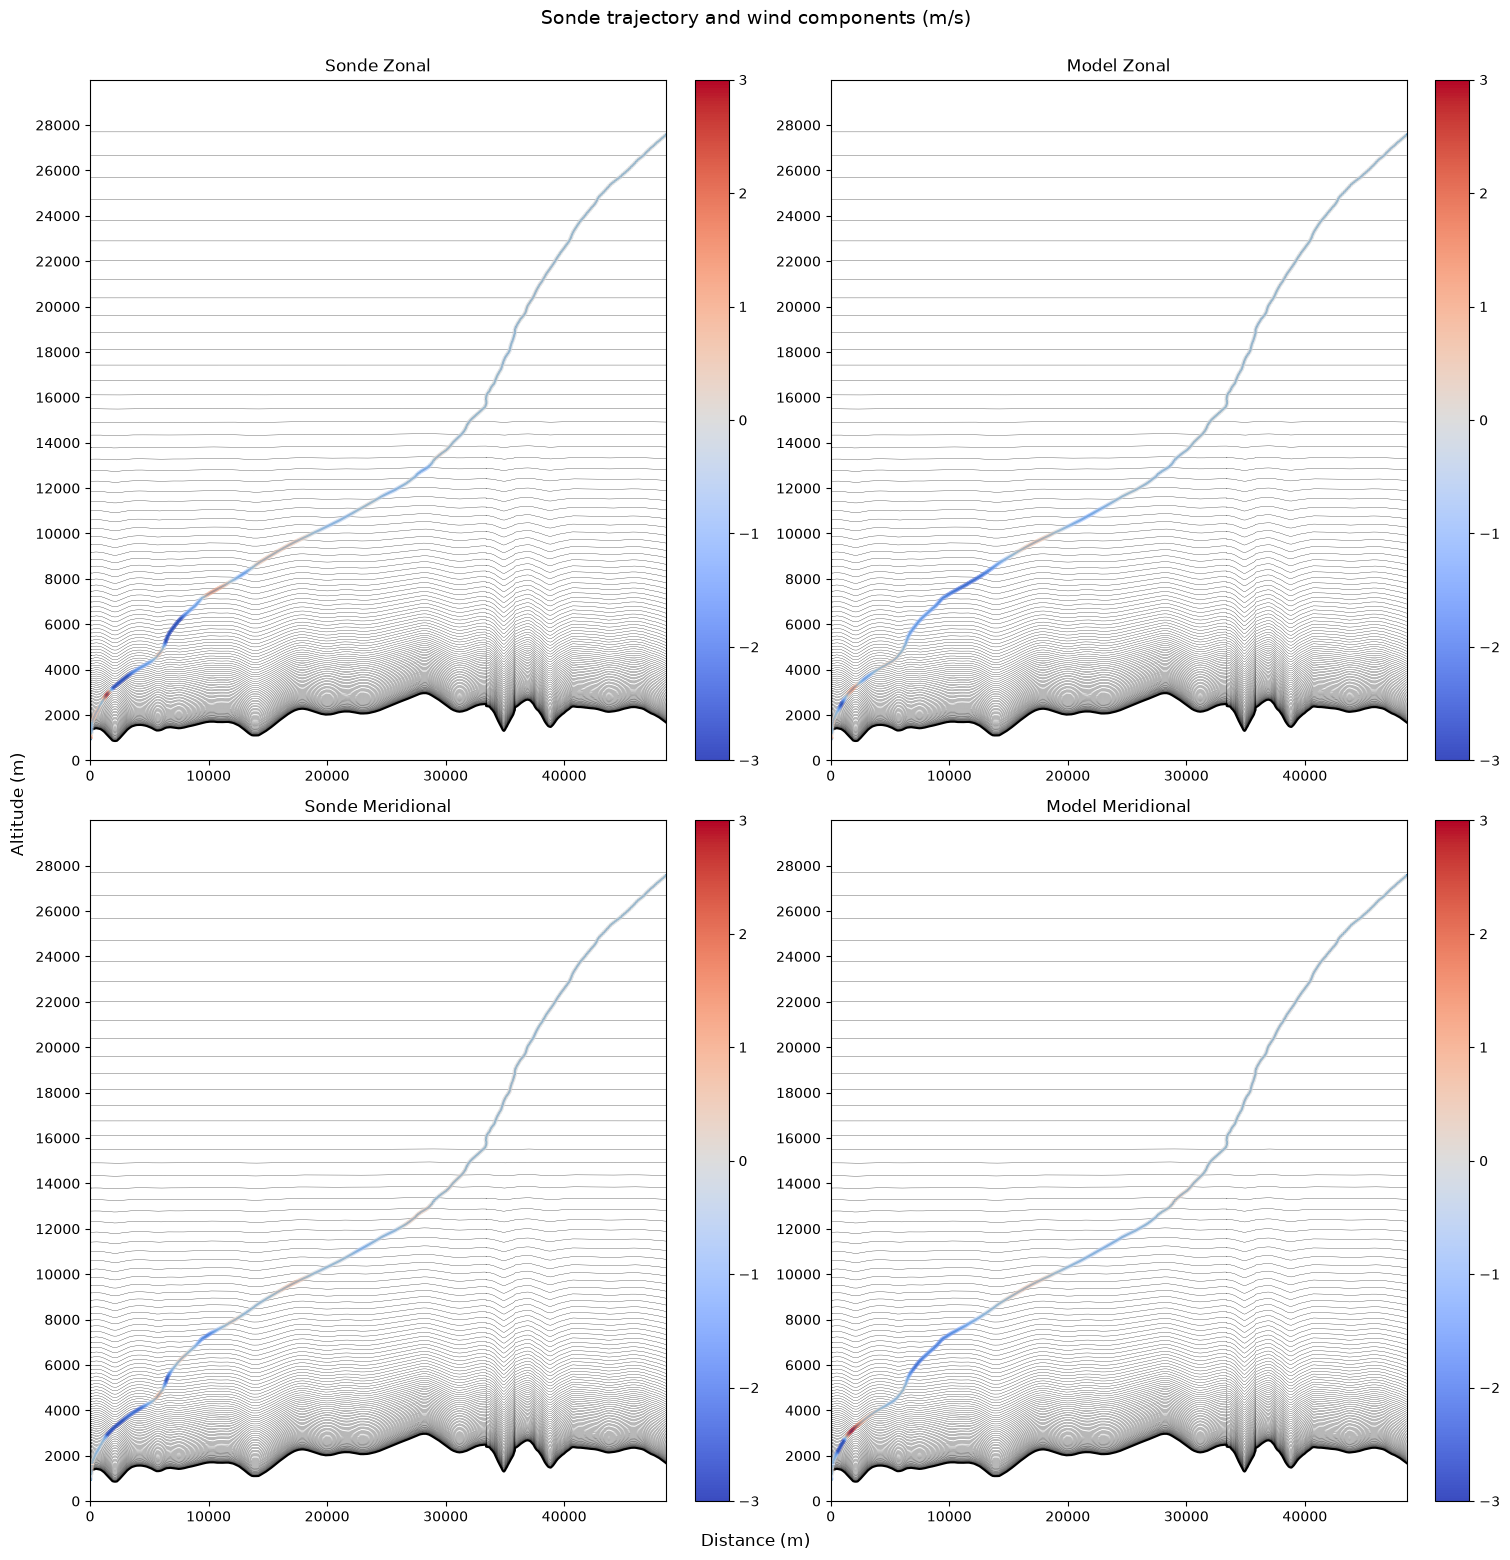

In [30]:
fig = plt.figure(figsize=(15,15), layout="constrained")
axes = fig.subplots(2,2).flatten()

wind_vars = [u_s_wind_nonans, u_m_wind_nonans, v_s_wind_nonans, v_m_wind_nonans]
Flux_vars = [Flux_u_s, Flux_u_m, Flux_v_s, Flux_v_m]
titles = ["Sonde Zonal", "Model Zonal", "Sonde Meridional", "Model Meridional"]
maxmins = [3, 3, 3, 3]

for ax, var, maxmin, title in zip(axes, Flux_vars, maxmins, titles):
    # Plot the vertical level lines
    for i in levs_list:
        ax.plot(distance, i, color="k", linewidth=0.2)

    # Plot the orography
    ax.plot(distance, orog, color="k")

    # Plot the sonde profile
    ax.plot(distance, alt_s)

    # Set up a norm for coloured profile
    wind_component = var

    points = np.array([distance, alt_s]).T.reshape(-1,1,2)
    norm = TwoSlopeNorm(vmin=-maxmin, vmax=maxmin, vcenter=0)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    # Create linecollection and add to plot
    lc = LineCollection(segments, cmap="coolwarm", norm=norm, linewidth=3)
    lc.set_array(wind_component)
    ax.add_collection(lc)
    cbar = fig.colorbar(mappable=lc, ax=ax)

    # Set up limits and ticks
    ax.set_ylim(0, 30000)
    ax.set_yticks(np.arange(0, 30000, 2000))
    ax.set_xlim(0, np.max(distance))

    ax.set_title(f"{title}")

fig.suptitle("Sonde trajectory and wind components (m/s)", fontsize=14, y=1.03)
fig.supxlabel("Distance (m)")
fig.supylabel("Altitude (m)")




In [16]:
# On the profile plots, superimpose arrows that indicate wind direction. 

# First, as a test, plot vertical arrows at every 10 points.

